pomyślnie wczytano 99600 rekordów z circle chart album :))

udział firm dystrybucyjnych w rynku sprzedaży albumów


C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:32: UserWarning: Glyph 261 (\N{LATIN SMALL LETTER A WITH OGONEK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:32: UserWarning: Glyph 324 (\N{LATIN SMALL LETTER N WITH ACUTE}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\anaconda3\envs\studia\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 261 (\N{LATIN SMALL LETTER A WITH OGONEK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\chlip\anaconda3\envs\studia\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 324 (\N{LATIN SMALL LETTER N WITH ACUTE}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


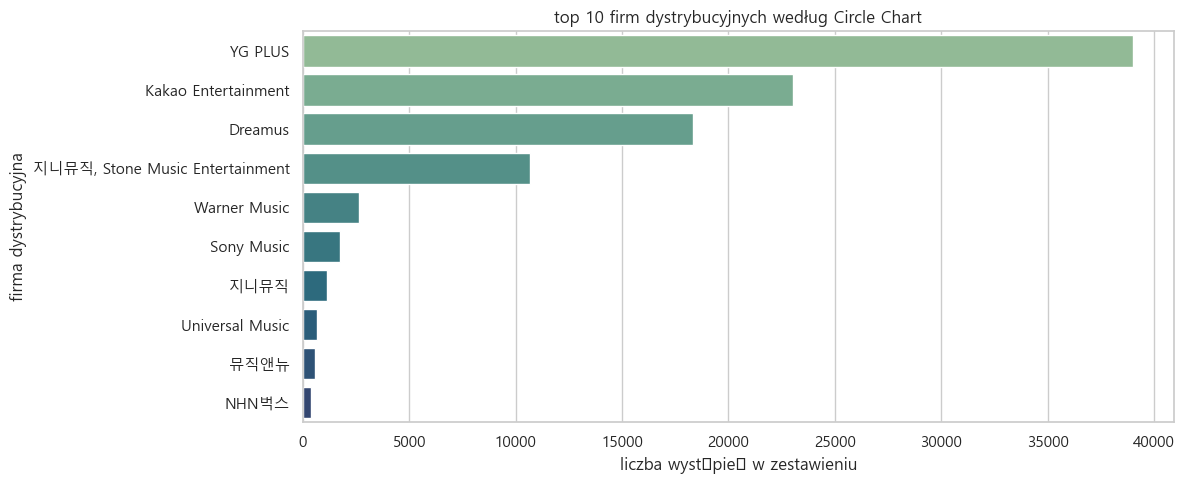


najczęściej wystepujący artyści w rankingu albumów


C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:44: UserWarning: Glyph 281 (\N{LATIN SMALL LETTER E WITH OGONEK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:44: UserWarning: Glyph 261 (\N{LATIN SMALL LETTER A WITH OGONEK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:44: UserWarning: Glyph 347 (\N{LATIN SMALL LETTER S WITH ACUTE}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\anaconda3\envs\studia\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 281 (\N{LATIN SMALL LETTER E WITH OGONEK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\chlip\anaconda3\envs\studia\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 261 (\N{LATIN SMALL LETTER A WITH OGONEK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(by

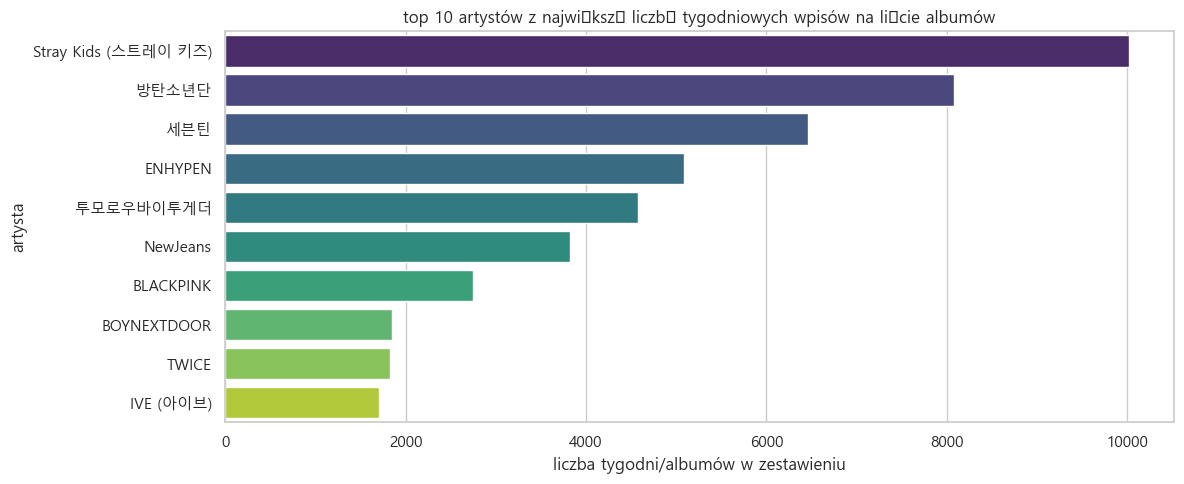


albumy najdłużej utrzymujące się w zestawieniu


C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:57: UserWarning: Glyph 281 (\N{LATIN SMALL LETTER E WITH OGONEK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:57: UserWarning: Glyph 261 (\N{LATIN SMALL LETTER A WITH OGONEK}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\AppData\Local\Temp\ipykernel_28940\2328929872.py:57: UserWarning: Glyph 347 (\N{LATIN SMALL LETTER S WITH ACUTE}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\Users\chlip\anaconda3\envs\studia\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 281 (\N{LATIN SMALL LETTER E WITH OGONEK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\chlip\anaconda3\envs\studia\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 261 (\N{LATIN SMALL LETTER A WITH OGONEK}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(by

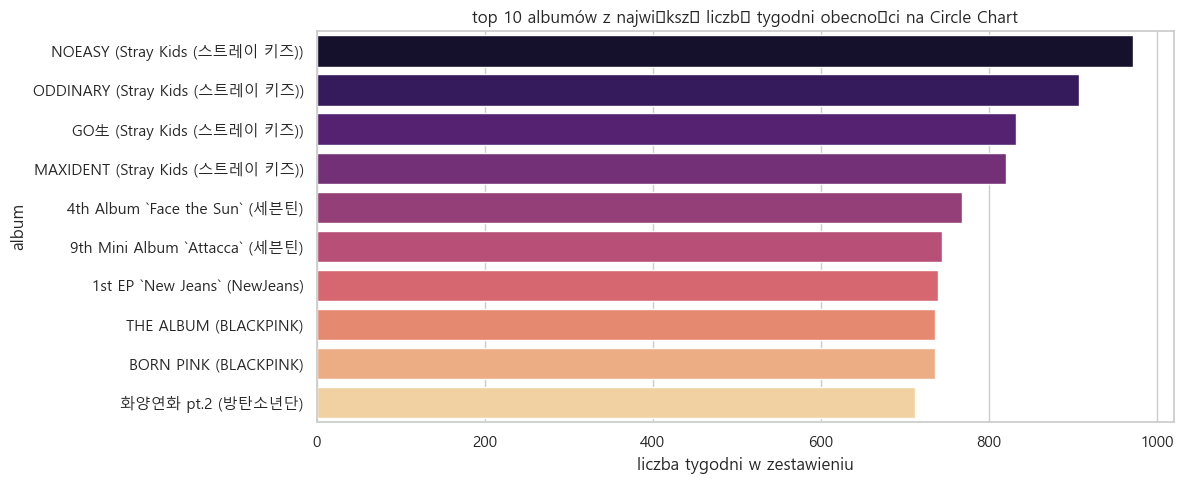

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pymongo import MongoClient

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# połączenie z MongoDB
client = MongoClient("mongodb://localhost:27017/")
db = client["kpop_db"]
collection_circle = db["circlechart_album_2022_2026"]

# pobieranie danych do dataframe
data_circle = list(collection_circle.find({}, {"_id": 0}))
df_circle = pd.DataFrame(data_circle)

df_circle.columns = df_circle.columns.str.replace('\ufeff', '').str.strip()
print(f"pomyślnie wczytano {len(df_circle)} rekordów z circle chart album :))")

print("\nudział firm dystrybucyjnych w rynku sprzedaży albumów")
top_companies = df_circle['DE_COMPANY_NAME'].value_counts().head(10).reset_index()
top_companies.columns = ['company_name', 'record_count']

plt.figure(figsize=(12, 5))
sns.barplot(data=top_companies, x='record_count', y='company_name', hue='company_name', palette="crest", legend=False)
plt.title('top 10 distribution companies')
plt.xlabel('record count')
plt.ylabel('distribution company')
plt.tight_layout()
plt.show()

print("\nnajczęściej wystepujący artyści w rankingu albumów")
top_artists_circle = df_circle['ARTIST_NAME'].value_counts().head(10).reset_index()
top_artists_circle.columns = ['artist_name', 'appearance_count']

plt.figure(figsize=(12, 5))
sns.barplot(data=top_artists_circle, x='appearance_count', y='artist_name', hue='artist_name', palette="viridis", legend=False)
plt.title("top 10 artystów z największą liczbą tygodniowych wpisów na liście albumów")
plt.xlabel("liczba tygodni/albumów w zestawieniu")
plt.ylabel("artysta")
plt.tight_layout()
plt.show()

print("\nalbumy najdłużej utrzymujące się w zestawieniu")
top_albums = df_circle.groupby(['ALBUM_NAME', 'ARTIST_NAME']).size().reset_index(name='weeks_on_chart')
top_albums = top_albums.sort_values(by='weeks_on_chart', ascending=False).head(10)
top_albums['album_label'] = top_albums['ALBUM_NAME'] + " (" + top_albums['ARTIST_NAME'] + ")"

plt.figure(figsize=(12, 5))
sns.barplot(data=top_albums, x='weeks_on_chart', y='album_label', hue='album_label', palette="magma", legend=False)
plt.title("top 10 albumów z największą liczbą tygodni obecności na Circle Chart")
plt.xlabel("liczba tygodni w zestawieniu")
plt.ylabel("album")
plt.tight_layout()
plt.show()